# AI4Habitats – a guided tour of the library

This notebook shows how to use the code base on the **toy subset** of the AI4Habitats data set:

1. Setup
2. Data Intro
3. Patchwise data loading
4. Pixelwise data loading
5. Train / validation / test splits
6. Models
7. Training
8. Results of a run
9. Inference & maps
10. Comparing many runs

To get the toy data (≈ 5 GB) next to this repository run:
```bash
wget https://phenoroam.phenorob.de/file-uploader/download/public/30205-download_ai4habitats.py -O download_ai4habitats.py
python download_ai4habitats.py --toy --out .
```

## 1. Setup

In [1]:
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import xarray as xr

warnings.filterwarnings("ignore")

REPO_DIR = os.path.abspath(".")                                         # repository root (this notebook's folder)
DATA_DIR = os.environ.get("AI4H_DATA", os.path.join(REPO_DIR, "data"))  # downloaded (toy) data
RESULTS_DIR = os.path.join(REPO_DIR, "results", "demo")                 # where the demo runs are written
META_FILE = os.path.join(DATA_DIR, "patches_meta.csv")

print(f"Repository directory: {REPO_DIR}")
print(f"Data directory: {DATA_DIR}")
print(f"Results directory: {RESULTS_DIR}")

sys.path.insert(0, REPO_DIR)
GPU = torch.cuda.is_available()
print(f"GPU available: {GPU}")

Repository directory: /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_ssd/essd_ai4habitats/
Data directory: /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_ssd/essd_ai4habitats/data
Results directory: /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_ssd/essd_ai4habitats/results/demo
GPU available: True


## 2. Data Intro 

`patches_meta.csv` lists one row per patch. `path_input` / `path_label` are relative to the CSV's folder; the library resolves them automatically, so the data folder can live anywhere.

In [2]:
meta = pd.read_csv(META_FILE)
print(f"{len(meta)} patches")
meta.head()

101 patches


,patch_id,lat,lon,central_date,path_input,path_label
0,29078,53.497608,10.183993,2019,sentinel/patch_29078.nc,labels/patch_29078.nc
1,29073,53.591066,10.031890,2017,sentinel/patch_29073.nc,labels/patch_29073.nc
2,28093,53.451208,10.221253,2021,sentinel/patch_28093.nc,labels/patch_28093.nc
3,28028,53.477535,9.836260,2022,sentinel/patch_28028.nc,labels/patch_28028.nc
4,29071,53.568386,9.992680,2017,sentinel/patch_29071.nc,labels/patch_29071.nc


Each patch consists of two NetCDF files: the Sentinel-2 stack (10 bands × 24 monthly composites, March–October of three years) and the label raster with the habitat code and covariates.

In [3]:
row = meta.iloc[0]
s2 = xr.open_dataarray(os.path.join(DATA_DIR, row.path_input))
lab = xr.open_dataset(os.path.join(DATA_DIR, row.path_label), mask_and_scale=False)
print(f"Sentinel-2 patch shape:  {dict(s2.sizes)}")
print(f"Natura 2000 patch shape: {dict(lab.sizes)}")

Sentinel-2 patch shape:  {'band': 10, 'time': 24, 'y': 256, 'x': 256}
Natura 2000 patch shape: {'y': 256, 'x': 256}


The habitat codes are corresponding to the Natura 2000 habitat types as defined in the `lrt_legend.csv` file.

In [4]:
legend = pd.read_csv(os.path.join(DATA_DIR, "lrt_legend.csv"), dtype=str)
legend.columns = ["lrt_code", "lrt_name", "lrt_color"]
legend.index = legend.index + 1
codes = lab["lrt_code"].values[lab["aoi_mask"].values == 1]
values, counts = np.unique(codes, return_counts=True)
labels = pd.DataFrame({"n_pixels": counts}, index=values)
labels = legend.join(labels, how="right").fillna({"lrt_code": "0", "lrt_name": "background (no habitat)"})
labels["share"] = (labels["n_pixels"] / labels["n_pixels"].sum()).round(3)
labels[["lrt_code", "lrt_name", "n_pixels", "share"]].rename_axis("encoded")

,lrt_code,lrt_name,n_pixels,share
encoded,,,,
0,0,background (no habitat),64449,0.983
48,2330,Dünen mit offenen Grasflächen mit Corynephorus...,338,0.005
65,3260,Flüsse der planaren bis montanen Stufe mit Veg...,129,0.002
96,6120,"Trockene, kalkreiche Sandrasen",2,0.000
117,6410,"Pfeifengraswiesen auf kalkreichem Boden, torfi...",92,0.001
123,6510,Magere Flachland-Mähwiesen (Alopecurus pratens...,265,0.004
169,9190,Alte bodensaure Eichenwälder auf Sandebenen mi...,198,0.003
177,91E0,Auen-Wälder mit Alnus glutinosa und Fraxinus e...,63,0.001


## 3. Patchwise data loading

`S2_Dataset` is a PyTorch dataset returning `(input, label, index)` per patch:

* **input**   
    – `(bands × time steps, H, W)`  
    – reflectance / 10 000, standardised channel-wise with `s2_normalization_stats.json`  
    – channels are band-major (`B2_y1-03, B2_y1-04, …`)  

* **label**  
    – `(H, W)` class indices for the chosen task  
    – `-99` = ignored (outside the area of interest and background for `_bec` tasks) 

`sel_task` selects the level of the habitat hierarchy:

In [5]:
from models.patchwise.data import S2_Dataset
tasks = ["lvl0_bic", "lvl1_bic", "lvl1_bec", "lvl2_bic", "lvl2_bec", "lvl4_bic", "lvl4_bec"]
rows = []
for task in tasks:
    ds = S2_Dataset(META_FILE, sel_task=task)
    _, y, _ = ds[0]
    to_label = ds.label_map_df.drop_duplicates("target_encoding").set_index("target_encoding")["target_semantics"]
    in_patch = sorted(set(y.unique().tolist()) - {-99})
    rows.append(dict(
        task=task,
        n_classes=len(ds.labels_unique) - task.endswith("_bec"),
        classes_in_patch=[str(to_label[c]) for c in in_patch],
    ))
pd.DataFrame(rows).rename(columns={"n_classes": "n_classes (maximal acc. to Natura 2000 taxonomy)"})

,task,n_classes (maximal acc. to Natura 2000 taxonomy),classes_in_patch
0,lvl0_bic,2,"[0, 1]"
1,lvl1_bic,10,"[0, 2, 3, 6, 9]"
2,lvl1_bec,9,"[2, 3, 6, 9]"
3,lvl2_bic,34,"[0, 23, 32, 61, 64, 65, 91]"
4,lvl2_bec,33,"[23, 32, 61, 64, 65, 91]"
5,lvl4_bic,234,"[0, 2330, 3260, 6120, 6410, 6510, 9190, 91E0]"
6,lvl4_bec,233,"[2330, 3260, 6120, 6410, 6510, 9190, 91E0]"


Inputs can be restricted to bands and/or time steps (`S2_Dataset.BAND_ORDER`, `S2_Dataset.TIME_ORDER`); the number of channels follows:

In [6]:
ds = S2_Dataset(
    META_FILE,
    sel_task="lvl2_bec",
    sel_band=["B8", "B4", "B3"],
    sel_time=["y2-04", "y2-06", "y2-08"]
)
x, y, _ = ds[0]
print("input", tuple(x.shape), "label", tuple(y.shape))
print(ds.channel_names)

input (9, 256, 256) label (256, 256)
['B8__y2-04', 'B8__y2-06', 'B8__y2-08', 'B4__y2-04', 'B4__y2-06', 'B4__y2-08', 'B3__y2-04', 'B3__y2-06', 'B3__y2-08']


With `read_covars=True` the dataset also returns the label covariates (polygon id, conservation status A/B/C = 1/2/3, time gap survey ↔ imagery in years; NaN where undefined). They enable a covariate-stratified evaluation if desired.

In [7]:
ds = S2_Dataset(META_FILE, sel_task="lvl2_bec", read_covars=True)
x, y, covars, _ = ds[0]
for name, c in zip(ds.COVAR_ORDER, covars):
    v = c[torch.isfinite(c)]
    print(f"{name:17s} defined on {v.numel():6d} px", f"range [{v.min():.2f}, {v.max():.2f}]" if v.numel() else "")

polygon_id        defined on   1087 px range [108828.00, 109040.00]
lrt_status        defined on   1087 px range [1.00, 3.00]
acquisition_date  defined on   1087 px range [-2.03, 2.06]


Examples can be visualized by calling the samples index, for instance:

Plotting sample 12 from dataset as RGB timeseries...
patch_id                                                    28024
lat                                                     53.454526
lon                                                      9.835808
central_date                                                 2022
path_input      /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_s...
path_label      /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_s...
Name: 12, dtype: object


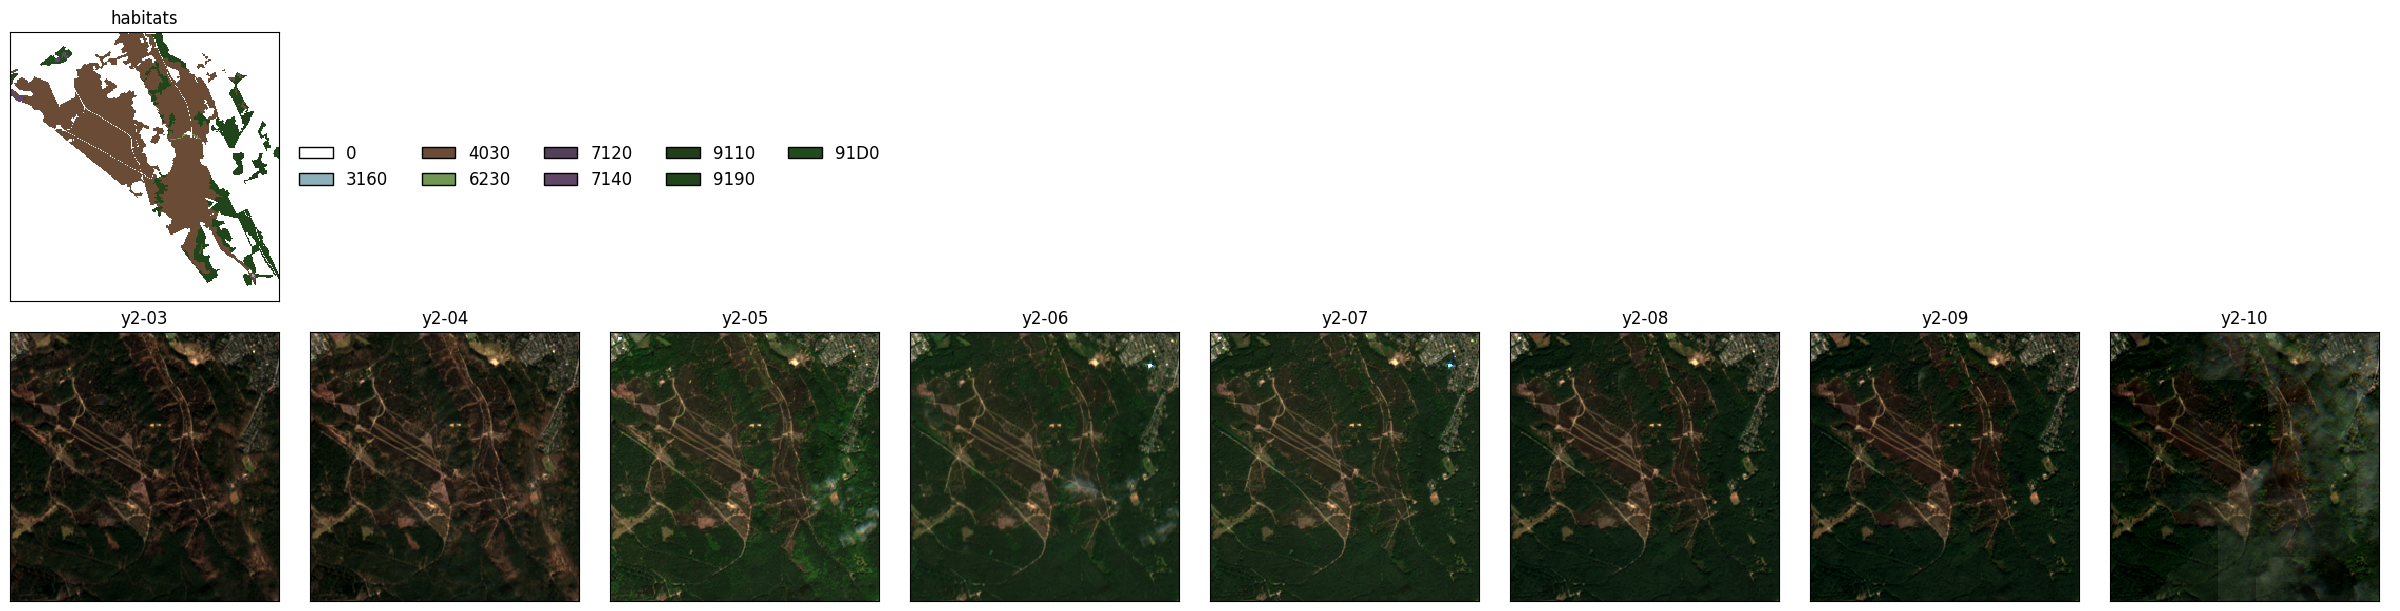

In [8]:
ds = S2_Dataset(META_FILE, sel_task="lvl4_bic", sel_time=S2_Dataset.TIME_ORDER[8:16])
fig, axs = ds.plot(12)
plt.show()

## 4. Pixelwise data loading

The pixelwise models classify single pixels from their `(bands, time steps)` stack. `TimeSeriesDatasetCreator` samples such stacks from the patches. `TimeSeriesDataset` exposes them as `X_train, y_train, X_val, …`.

In [9]:
from models.pixelwise.data import TimeSeriesDatasetCreator, TimeSeriesDataset

tsdc = TimeSeriesDatasetCreator(META_FILE, sel_task="lvl2_bec", sample_size=5000, seed=42)
pix = TimeSeriesDataset(tsdc.run())
print("X_train", pix.X_train.shape, " y_train", pix.y_train.shape, " X_test", pix.X_test.shape)
print("classes in train:", np.unique(pix.y_train))

Sampling test pixels: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:05<00:00,  2.99it/s]

X_train (5000, 10, 24)  y_train (5000,)  X_test (809, 10, 24)
classes in train: [ 9 10 11 12 17 18 20 21 22 23 29]


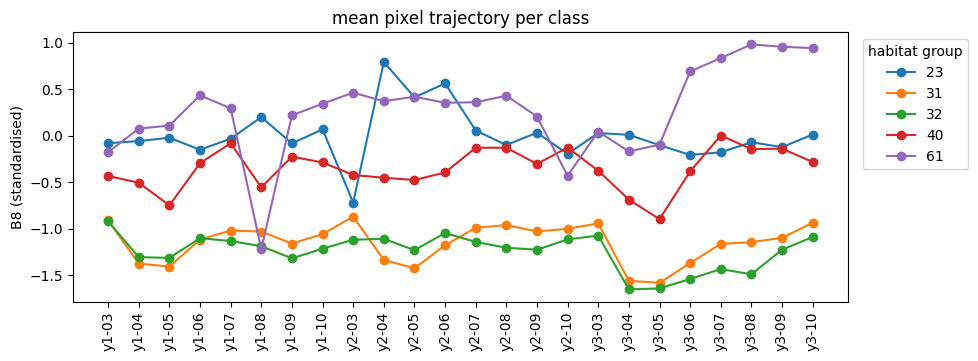

In [10]:
band = "B8"
b = S2_Dataset.BAND_ORDER.index(band)
fig, ax = plt.subplots(figsize=(10, 3.5))
for cls in np.unique(pix.y_train)[:5]:
    ax.plot(pix.X_train[pix.y_train == cls, b].mean(0), marker="o", label=pix.labels_str[cls])
ax.set_xticks(range(len(S2_Dataset.TIME_ORDER)), S2_Dataset.TIME_ORDER, rotation=90)
ax.set_ylabel(f"{band} (standardised)")
ax.legend(title="habitat group", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("mean pixel trajectory per class")
plt.show()

## 5. Splits

`SplitGenerator` assigns patches to train / validation / test. `random` splits patch-wise; `spatial-block` assigns whole grid cells (default 25.6 km) to one split, which avoids spatial leakage between neighbouring patches. The trainers call it internally (`split_strategy`, `split_trainsize`, `split_kwargs`, `seed`). Different seeds give different splits.

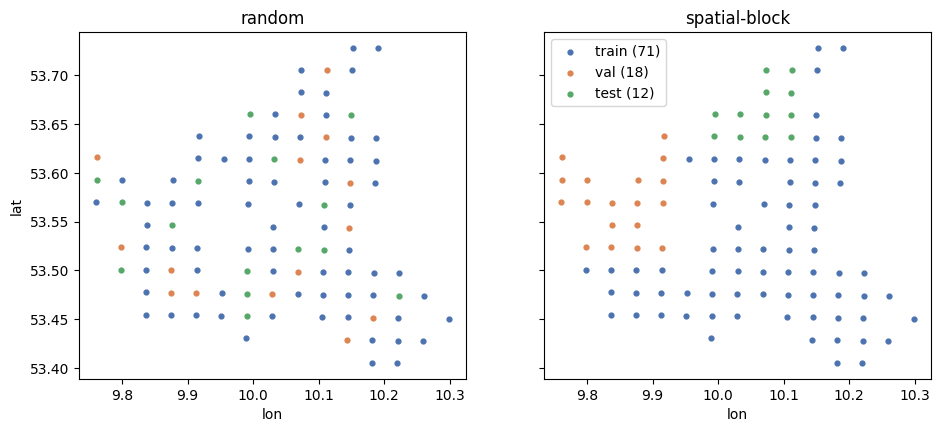

,n_patches,share,target_share
split,,,
train,71,0.702970,0.70
val,18,0.178218,0.15
test,12,0.118812,0.15


In [11]:
from models.patchwise.crossval import SplitGenerator

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (strategy, kw) in zip(axs, [("random", {}), ("spatial-block", {"grid_distance": 12800})]):
    sg = SplitGenerator(META_FILE, strategy=strategy, trainsize=0.7, seed=42, **kw)
    df = sg.generate()
    for split, color in zip(["train", "val", "test"], ["#4c72b0", "#dd8452", "#55a868"]):
        d = df[df.split == split]
        ax.scatter(d.lon, d.lat, s=12, c=color, label=f"{split} ({len(d)})")
    ax.set_title(f"{strategy}"); ax.set_xlabel("lon")
axs[0].set_ylabel("lat"); axs[1].legend()
plt.show()
sg.summary_

## 6. Models

* **Patchwise:** any [segmentation-models-pytorch](https://smp.readthedocs.io) architecture & encoder (`SegmentationModel`)
* **Pixelwise DL:** sktime time-series classifiers in TensorFlow or PyTorch (`TempModelConfigurator`)
* **Pixelwise ML:** cuML estimators with default configurations and search spaces (`MLModelConfigurator`)

In [12]:
from models.patchwise.model import SegmentationModel

example_models = dict(
    Unet = "resnet18",
    DeepLabV3Plus = "resnet50",
    Segformer = "mit_b0",
    DPT = "tu-vit_base_patch16_224.augreg_in21k",
)

rows = []
for model_name, backbone in example_models.items():
    sm = SegmentationModel(model_name=model_name, encoder_name=backbone, encoder_weights=None, in_channels=240, num_classes=34)
    sm.init_model()
    sm.summarize(verbose=False)
    rows.append(dict(model=model_name, params=sm.summary_stats["total_params"]))
pd.DataFrame(rows).sort_values("params").reset_index(drop=True)

,model,params
0,Segformer,4094498
1,Unet,15076226
2,DeepLabV3Plus,27429298
3,DPT,184410997


In [13]:
from IPython.utils.capture import capture_output
from models.pixelwise.deep_learning.model import TempModelConfigurator

rows = []
with capture_output():
    for name, lib in TempModelConfigurator.MODELS.items():
        tmc = TempModelConfigurator(name, n_timesteps=24, n_features=10, num_classes=34)
        tmc.init_model()
        tmc.summarize(verbose=False)
        rows.append(dict(model=name, library=lib, params=tmc.summary_stats["total_params"]))
pd.DataFrame(rows).sort_values("params").reset_index(drop=True)

2026-10-27 17:48:54.946510: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-27 17:48:55.001363: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-27 17:48:55.001798: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-27 17:48:55.096615: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-27 17:48:56.529151: W tensorflow/compiler/tf

,model,library,params
0,cnn,tensorflow,1792
1,convtran,pytorch,216730
2,fcn,tensorflow,279330
3,lstm_fcn,tensorflow,290898
4,mcdcnn,tensorflow,380774
5,inception,tensorflow,497826
6,mvts,pytorch,506402
7,resnet,tensorflow,516130
8,mlp,tensorflow,638534
9,tapnet,tensorflow,2986078


In [14]:
from models.pixelwise.machine_learning.model import MLModelConfigurator

try:
    for model in MLModelConfigurator.MODELS:
        MLModelConfigurator.describe(model)
except ImportError as e:
    print("cuML not available:", e)


=== rf (cuml) ===
default configuration (tuning=None):
  n_estimators            100
  split_criterion         gini
  max_depth               16
  max_features            sqrt
  min_samples_leaf        1
  min_samples_split       2
  bootstrap               True
  max_samples             1.0
  n_bins                  128
  n_streams               4
  class_weights           None
grid search space:
  n_estimators            [100, 300, 500]
  max_depth               [8, 16, 24]
  max_features            ['sqrt', 'log2']
  min_samples_leaf        [1, 2, 4, 8]
  class_weights           [None, 'sqrt']
randomised search space:
  n_estimators            rv_discrete_frozen
  max_depth               rv_discrete_frozen
  max_features            rv_continuous_frozen
  min_samples_leaf        rv_discrete_frozen
  class_weights           [None, 'sqrt']

=== knn (cuml) ===
default configuration (tuning=None):
  n_neighbors             5
  algorithm               brute
  metric                  eucl

## 7. Training

All three trainers share the interface `Trainer(**config)` → `prep_model()` → `train_model()`.  
Data arguments (`meta_file`, `sel_task`, `sel_band`, `sel_time`, `split_*`, `seed`) are identical across trainers.
Model arguments differ.   
Everything a run produces goes to `save_dir`.  
Set `wandb_project` to log to Weights & Biases.

One relevant option to speed up training is to set the flag `use_cache="disk`. This way data that has been read in the first epoch during training will be stored in a .cache folder next to the data set. **Be aware: This effectively duplicates data and thus increases the disk space required to store the data set**.

The settings below are tiny so the demo finishes in minutes.
The same runs can be started from the command line,  
e.g. `python scripts/patch_train.py --meta_file data/patches_meta.csv --sel_task lvl2_bec --max_epochs 3`.

In [15]:
COMMON = dict(meta_file=META_FILE, sel_task="lvl2_bec", use_cache="disk", seed=42, wandb_project=None)
RUNS = {
    "patch_unet": ("models.patchwise.train",
                   dict(model_name="Unet", encoder_name="resnet18", encoder_weights=None,
                        loss="CrossEntropyLoss", lr=1e-3, max_epochs=3, batch_size=8)),
    "pixel_fcn": ("models.pixelwise.deep_learning.train",
                  dict(model_name="fcn", loss="CrossentropyLoss", lr=1e-3, max_epochs=3, n_samples=50_000)),
    "ml_rf": ("models.pixelwise.machine_learning.train",
              dict(model_name="rf", n_samples=50_000, tuning=None)),
}

In [16]:
import importlib

if GPU:
    for run, (module, cfg) in RUNS.items():
        Trainer = importlib.import_module(module).Trainer
        trainer = Trainer(**COMMON, **cfg, save_dir=os.path.join(RESULTS_DIR, run))
        trainer.prep_model()
        trainer.train_model()
        del trainer
else:
    print("No GPU: training skipped. Point RUN_DIR below to a finished run to continue.")

Generating train/val/test splits
- split strategy 'random'
- train size 0.7
- fold 0
       n_patches     share  target_share
split                                   
train         71  0.702970          0.70
val           15  0.148515          0.15
test          15  0.148515          0.15
Layer (type:depth-idx)                        Input Shape               Output Shape              Param #                   Trainable
Unet                                          [1, 240, 256, 256]        [1, 34, 256, 256]         --                        True
├─ResNetEncoder: 1-1                          [1, 240, 256, 256]        [1, 240, 256, 256]        --                        True
│    └─Conv2d: 2-1                            [1, 240, 256, 256]        [1, 64, 128, 128]         752,640                   True
│    └─BatchNorm2d: 2-2                       [1, 64, 128, 128]         [1, 64, 128, 128]         128                       True
│    └─ReLU: 2-3                              [1, 64, 128, 1

Iterate over batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:09<00:00,  1.09s/it]


train	 loss: 0.1547, num_samples: 71.0000, micro_f1: 0.2987, macro_f1: 0.0252, micro_precision: 0.2987, macro_precision: 0.0480, micro_recall: 0.2987, macro_recall: 0.0215, micro_iou: 0.1756, macro_iou: 0.0184, micro_acc: 0.2987, macro_acc: 0.0215


Iterate over batches: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2/2 [00:03<00:00,  1.95s/it]


val	 loss: 2.0149, num_samples: 15.0000, micro_f1: 0.0018, macro_f1: 0.0008, micro_precision: 0.0018, macro_precision: 0.0522, micro_recall: 0.0018, macro_recall: 0.0005, micro_iou: 0.0009, macro_iou: 0.0004, micro_acc: 0.0018, macro_acc: 0.0005


...

 Trainable params: 278,306 (1.06 MB)

 Non-trainable params: 1,024 (4.00 KB)


Epoch 1: LearningRateScheduler setting learning rate to 0.0005.
Epoch 1/3


2026-10-27 17:50:02.873460: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


152/156 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.9822 - macro_f1: 0.1222 - micro_acc: 0.7570
Epoch 1: val_loss improved from None to 1.04567, saving model to /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_ssd/essd_ai4habitats/results/demo/pixel_fcn/checkpoints/model.keras

Epoch 1: finished saving model to /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_ssd/essd_ai4habitats/results/demo/pixel_fcn/checkpoints/model.keras
156/156 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - loss: 0.9737 - macro_f1: 0.1230 - micro_acc: 0.7591 - val_loss: 1.0457 - val_macro_f1: 0.1384 - val_micro_acc: 0.8178 - learning_rate: 5.0000e-04

Epoch 2: LearningRateScheduler setting learning rate to 0.001.
Epoch 2/3
154/156 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5869 - macro_f1: 0.1473 - micro_acc: 0.8185
Epoch 2: val_loss improved from 1.04567 to 0.64961, saving model to /lustre/mlnvme/data/s39fkroe_hpc-ai4habitats_ssd/essd_ai4habitats/results/demo/pixel_fcn/checkpoints/model.keras

Epoch 2: finished saving model to /lus

## 8. Results of a run

A finished run folder contains

| file | content |
|---|---|
| `config.json` | Trainer arguments, rebuild with `Trainer.from_config(...)` |
| `model_params.pt` / `checkpoints/` | best checkpoint (minimum validation loss) |
| `model_loss.csv`, `model_metrics.csv` | per-epoch loss and training-stage metrics |
| `{train,val,test}/confusion_matrix.csv, report.csv` | final evaluation per split |
| `{val,test}/covariates/` | metrics stratified by conservation status and survey ↔ imagery time gap |
| `training_completed.txt` | written last, marks a complete run |

In [19]:
RUN_DIR = os.path.join(RESULTS_DIR, "patch_unet")      # any finished run
if os.path.isfile(os.path.join(RUN_DIR, "training_completed.txt")):
    report = pd.read_csv(os.path.join(RUN_DIR, "test", "report.csv"), index_col=0)
    display(report.tail(3))
else:
    print(f"no finished run in {RUN_DIR}")

,precision,recall,f1-score,support
accuracy,0.4456,0.4456,0.4456,0
macro avg,0.0948,0.0893,0.0640,38349
weighted avg,0.2844,0.4456,0.2981,38349


## 9. Inference and maps

Rebuild a trained model from its folder, predict a few patches and plot input, reference, prediction and confidence. The same works for the pixelwise trainers (`apply_model(meta_df=..., model_params=...)`); their per-pixel predictions are folded back into maps.

Generating train/val/test splits
- split strategy 'random'
- train size 0.7
- fold 0
       n_patches     share  target_share
split                                   
train         71  0.702970          0.70
val           15  0.148515          0.15
test          15  0.148515          0.15
Layer (type:depth-idx)                        Input Shape               Output Shape              Param #                   Trainable
Unet                                          [1, 240, 256, 256]        [1, 34, 256, 256]         --                        True
├─ResNetEncoder: 1-1                          [1, 240, 256, 256]        [1, 240, 256, 256]        --                        True
│    └─Conv2d: 2-1                            [1, 240, 256, 256]        [1, 64, 128, 128]         752,640                   True
│    └─BatchNorm2d: 2-2                       [1, 64, 128, 128]         [1, 64, 128, 128]         128                       True
│    └─ReLU: 2-3                              [1, 64, 128, 1

Inference on 4 samples: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.02s/it]


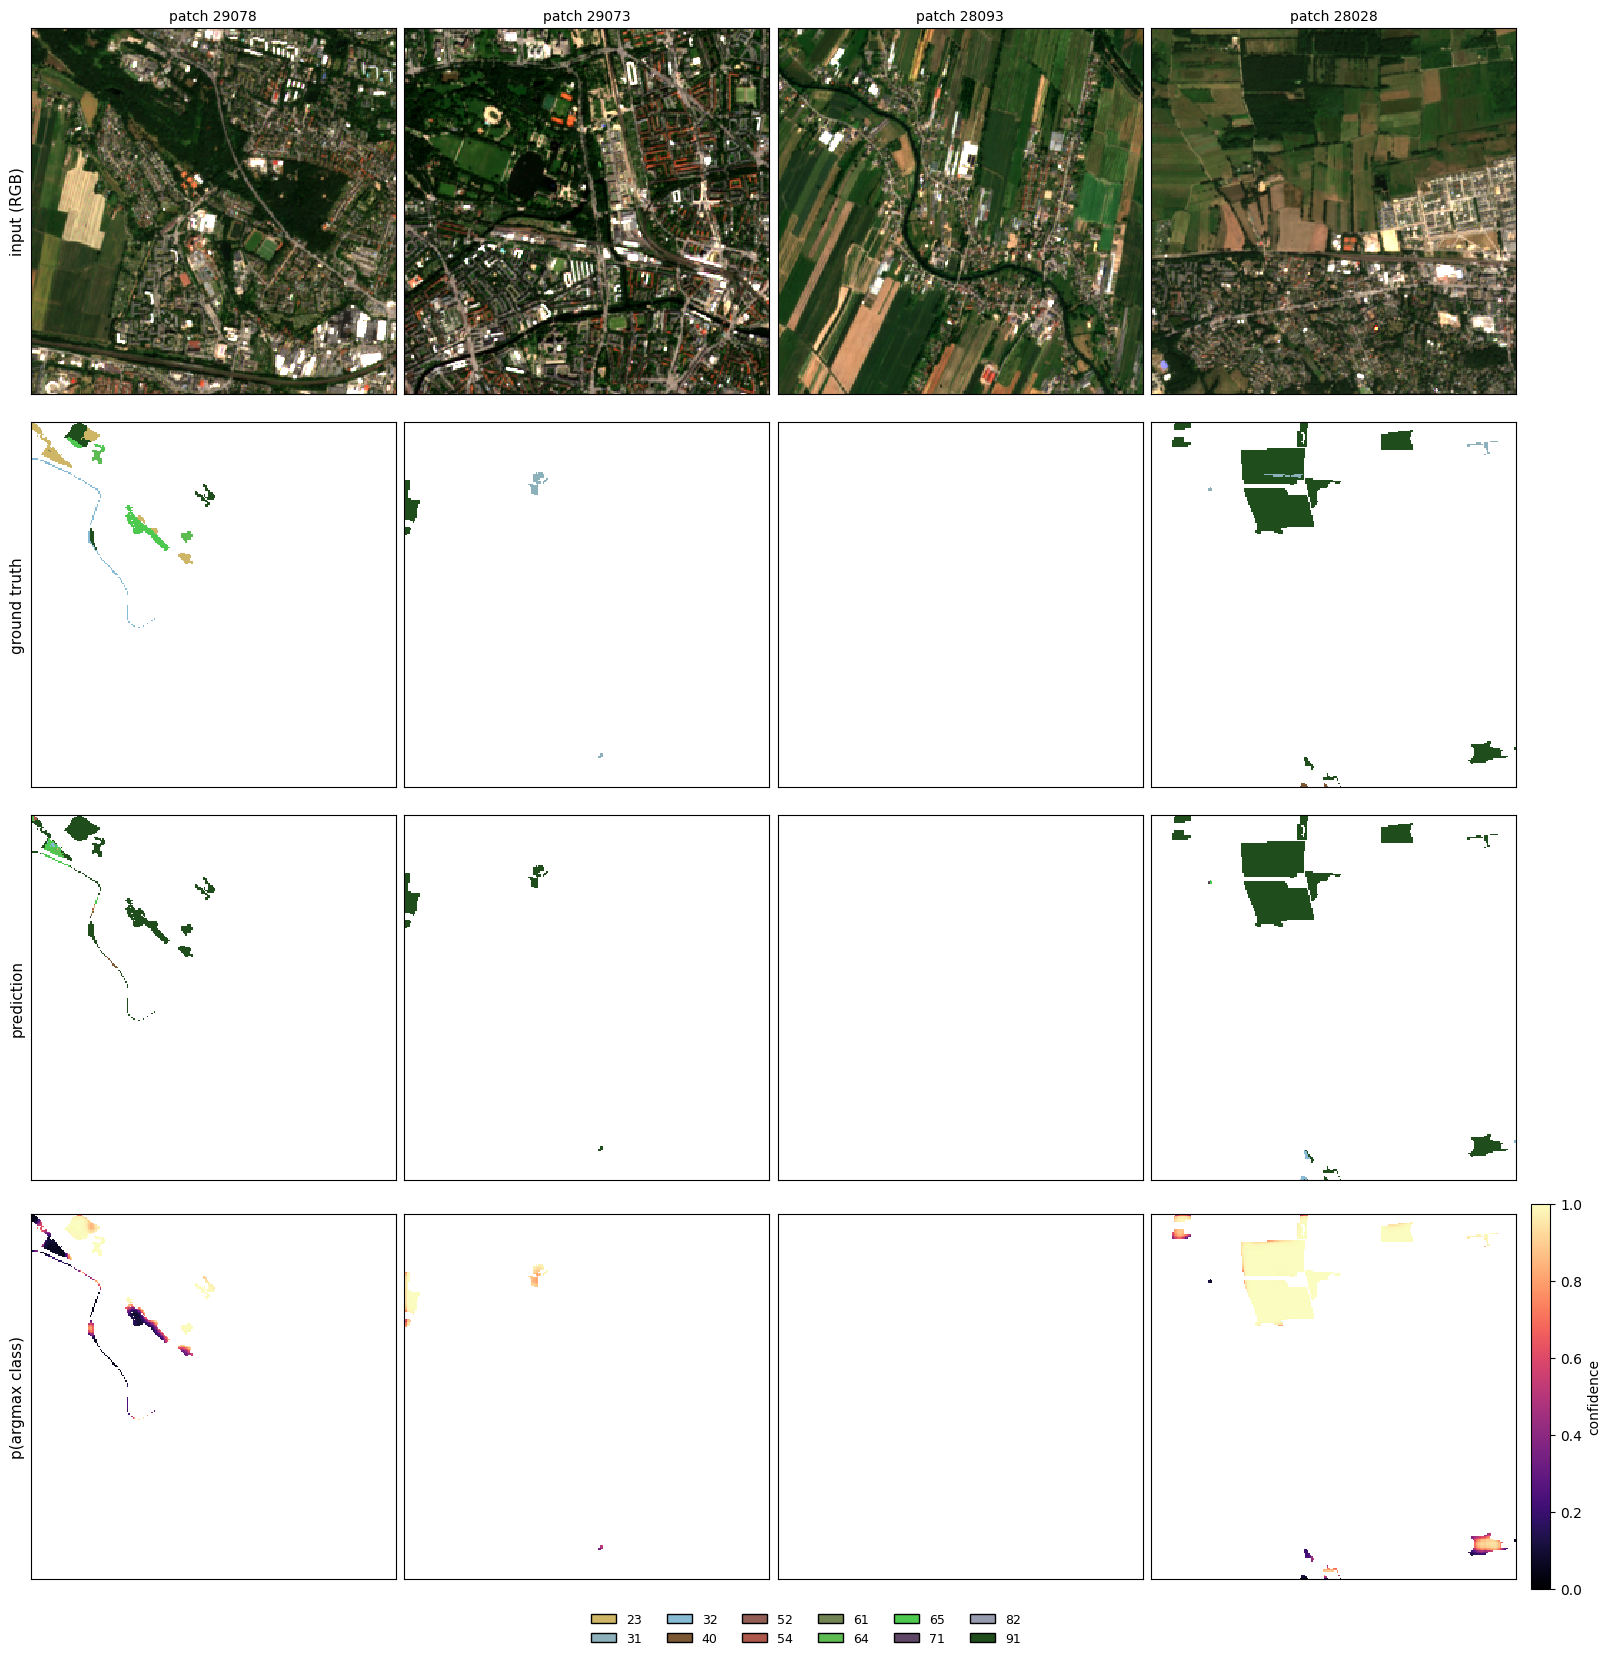

In [18]:
from models.visualize import plot_samples

if GPU and os.path.isfile(os.path.join(RUN_DIR, "training_completed.txt")):
    from models.patchwise.train import Trainer
    trainer = Trainer.from_config(os.path.join(RUN_DIR, "config.json"), wandb_project=None)
    patches = pd.read_csv(META_FILE).head(4)            # relative paths are resolved automatically
    res, ds = trainer.apply_model(meta_df=patches, model_params=os.path.join(RUN_DIR, "model_params.pt"),
                                  eval_metrics=False, return_res=True)
    plot_samples(res, ds)

## 10. Comparing many runs

`ResultsParser` collects all runs below a results folder, joins them with their final metrics from Weights & Biases (runs must have been logged with `wandb_project`) and returns tidy tables:

```python
from models.inspect import ResultsParser
res = ResultsParser("results/paper", project="ai4habitats", entity="<your W&B entity>")
res.describe()           # which hyper-parameters vary
res.summary              # config + final metrics, one row per run
res.curves               # per-epoch losses & metrics
```

`paper_eval.ipynb` uses it to produce the figures of the paper.